### MVTec AD data exploration

In [4]:
from pathlib import Path
import os
DATASET_DIR = Path.home() / r"repos/mvtech-ad\data/mvtec_anomaly_detection"

In [8]:
from pathlib import Path

def extract_metadata(image_path: Path) -> dict:
    defect_type = image_path.parent.name
    split = image_path.parent.parent.name
    product = image_path.parent.parent.parent.name

    return {
        "image_path": str(image_path),
        "product": product,
        "source_split": split,
        "inspection_result": (
            "normal" if defect_type == "good" else "defective"
        ),
        "defect_type": (
            "none" if defect_type == "good" else defect_type
        ),
    }

#### 1. Extract metadata for all images

In [9]:
import pandas as pd

metadata = []

for image_path in DATASET_DIR.rglob("*.png"):
    # Only process images from train/ and test/
    if image_path.parent.parent.name not in {"train", "test"}:
        continue

    metadata.append(extract_metadata(image_path))

df = pd.DataFrame(metadata)

print(df.head())
print(f"Total images: {len(df)}")

                                          image_path product source_split  \
0  C:\Users\akash\repos\mvtech-ad\data\mvtec_anom...  bottle         test   
1  C:\Users\akash\repos\mvtech-ad\data\mvtec_anom...  bottle         test   
2  C:\Users\akash\repos\mvtech-ad\data\mvtec_anom...  bottle         test   
3  C:\Users\akash\repos\mvtech-ad\data\mvtec_anom...  bottle         test   
4  C:\Users\akash\repos\mvtech-ad\data\mvtec_anom...  bottle         test   

  inspection_result   defect_type  
0         defective  broken_large  
1         defective  broken_large  
2         defective  broken_large  
3         defective  broken_large  
4         defective  broken_large  
Total images: 5354


#### 2. Map defective images to ground-truth mask to obtain defect location and description

In [10]:
from pathlib import Path
import pandas as pd

def get_mask_path(row):
    if row["inspection_result"] == "normal":
        return None

    image_path = Path(row["image_path"])

    mask_path = (
        DATASET_DIR
        / row["product"]
        / "ground_truth"
        / row["defect_type"]
        / f"{image_path.stem}_mask.png"
    )

    return str(mask_path) if mask_path.is_file() else None

df["mask_path"] = df.apply(get_mask_path, axis=1)

In [11]:
# Verify the mask mapping
defective = df[df["inspection_result"] == "defective"]

print("Total images:", len(df))
print("Defective images:", len(defective))
print("Masks found:", defective["mask_path"].notna().sum())
print("Missing masks:", defective["mask_path"].isna().sum())

Total images: 5354
Defective images: 1258
Masks found: 1258
Missing masks: 0


In [12]:
# Extract defection locations from masks by dividing image in 3x3 grid and selecting a location with dense mask
import cv2
import numpy as np
import pandas as pd

def extract_defect_location(mask_path):
    if pd.isna(mask_path):
        return "none"

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(mask_path)

    binary_mask = mask > 0
    ys, xs = np.where(binary_mask)

    if len(xs) == 0:
        return "none"

    height, width = mask.shape

    x_norm = xs.mean() / width
    y_norm = ys.mean() / height

    columns = ["left", "center", "right"]
    rows = ["upper", "middle", "lower"]

    col_idx = min(int(x_norm * 3), 2)
    row_idx = min(int(y_norm * 3), 2)

    if row_idx == 1 and col_idx == 1:
        return "center"

    return f"{rows[row_idx]}_{columns[col_idx]}"


df["location"] = df["mask_path"].apply(extract_defect_location)

print(df[["product", "inspection_result", "defect_type", "location"]].head(10))

  product inspection_result   defect_type      location
0  bottle         defective  broken_large   lower_right
1  bottle         defective  broken_large  lower_center
2  bottle         defective  broken_large        center
3  bottle         defective  broken_large        center
4  bottle         defective  broken_large   middle_left
5  bottle         defective  broken_large  middle_right
6  bottle         defective  broken_large  upper_center
7  bottle         defective  broken_large        center
8  bottle         defective  broken_large  lower_center
9  bottle         defective  broken_large  middle_right


In [ ]:
print(df["location"].value_counts())
print(pd.crosstab(df["inspection_result"], df["location"]))

location
none            4096
center           540
middle_right     192
upper_center     131
middle_left      128
lower_center     126
lower_left        47
upper_right       34
upper_left        33
lower_right       27
Name: count, dtype: int64
location           center  lower_center  lower_left  lower_right  middle_left  \
inspection_result                                                               
defective             540           126          47           27          128   
normal                  0             0           0            0            0   

location           middle_right  none  upper_center  upper_left  upper_right  
inspection_result                                                             
defective                   192     0           131          33           34  
normal                        0  4096             0           0            0  


In [14]:
# Generate the description
def generate_description(row: dict) -> str:
    product = row["product"].replace("_", " ")
    defect_type = row["defect_type"].replace("_", " ")
    location = row["location"].replace("_", " ")
    if row["inspection_result"] == "normal":
        return f"No annotated defects are present in the {product} image."
    return (f"The {product} image contains a {defect_type} defect, primarily located in the {location} region.")


df["description"] = df.apply(generate_description, axis=1)

In [15]:
report_columns = ["product", "inspection_result", "defect_type", "location", "description"]
print(df[report_columns].sample(10, random_state=42).to_string(index=False))

   product inspection_result   defect_type    location                                                                                   description
    zipper         defective fabric_border      center     The zipper image contains a fabric border defect, primarily located in the center region.
      grid            normal          none        none                                           No annotated defects are present in the grid image.
     cable            normal          none        none                                          No annotated defects are present in the cable image.
toothbrush         defective     defective      center     The toothbrush image contains a defective defect, primarily located in the center region.
      grid            normal          none        none                                           No annotated defects are present in the grid image.
    bottle         defective  broken_small upper_right The bottle image contains a broken small defect, pr

#### 3. Visualize a representative sample to confirm visual accuracy

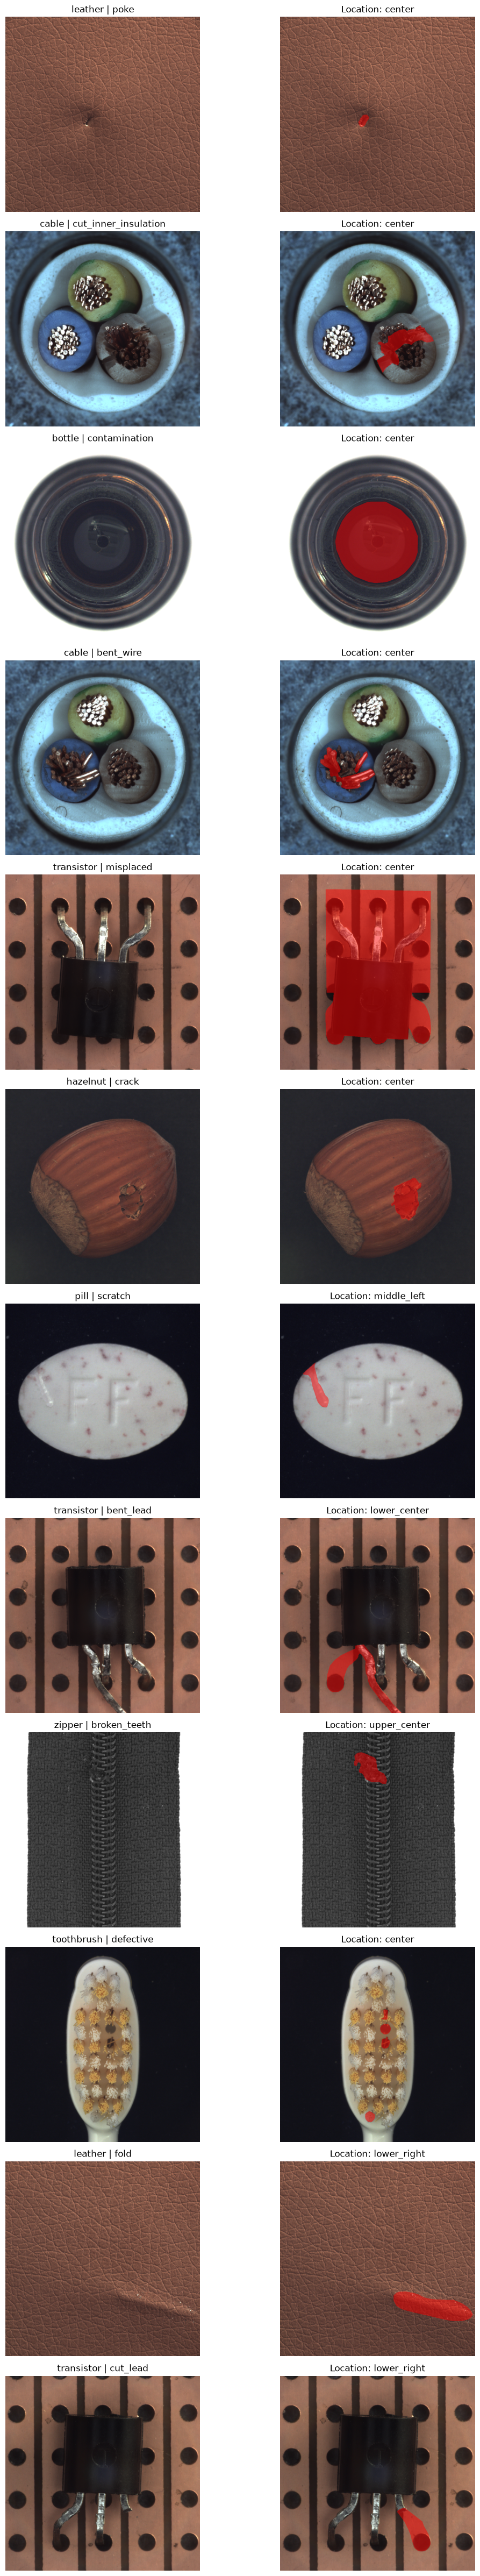

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


def visualize_reports(df, n_samples=12, seed=42):
    defective_df = df[df["inspection_result"] == "defective"]
    samples = defective_df.sample(n=min(n_samples, len(defective_df)), random_state=seed)

    fig, axes = plt.subplots(len(samples), 2, figsize=(12, 4 * len(samples)), squeeze=False)

    for i, (_, row) in enumerate(samples.iterrows()):
        # Read original image
        image = cv2.imread(str(row["image_path"]))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        # Read ground-truth segmentation mask
        mask = cv2.imread(str(row["mask_path"]), cv2.IMREAD_GRAYSCALE)

        if mask is None:
            raise FileNotFoundError(row["mask_path"])

        binary_mask = mask > 0
        # Create red defect overlay
        overlay = image.copy()
        overlay[binary_mask] = (0.5 * overlay[binary_mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
        # Original
        axes[i, 0].imshow(image)
        axes[i, 0].set_title(f"{row['product']} | {row['defect_type']}")
        # Ground-truth overlay
        axes[i, 1].imshow(overlay)
        axes[i, 1].set_title(f"Location: {row['location']}")

        for ax in axes[i]:
            ax.axis("off")

        axes[i, 1].set_xlabel(row["description"], fontsize=9, wrap=True)

    plt.tight_layout()
    plt.show()


visualize_reports(df, n_samples=12)


#### 4. Convert the data frame to JSON for report generation

In [18]:
import json

REPORT_COLUMNS = ["product", "inspection_result", "defect_type", "location", "description"]

output_dir = DATASET_DIR.parent / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "image_reports.jsonl"

with output_path.open("w", encoding="utf-8") as f:
    for _, row in df.iterrows():
        record = {"image_path": str(row["image_path"]), "report": {key: row[key] for key in REPORT_COLUMNS}}
        f.write(json.dumps(record) + "\n")

print(f"Saved {len(df)} reports to {output_path}")

Saved 5354 reports to C:\Users\akash\repos\mvtech-ad\data\processed\image_reports.jsonl
